
# Surrogate Models

Some industrial applications require modeling complex processes that can
result either in highly nonlinear functions or functions defined by a
simulation process. In those contexts, optimization solvers often
struggle. The reason may be that relaxations of the nonlinear functions
are not good enough to make the solver prove an acceptable bound in a
reasonable amount of time. Another issue may be that the solver is not
able to represent the functions.

An approach that has been proposed in the literature is to approximate
the problematic nonlinear functions via neural networks with ReLU
activation and use MIP technology to solve the constructed approximation
(see e.g. \ [Heneao Maravelias
2011](https://doi.org/https://doi.org/10.1002/aic.12341)_\ ,
[Schweitdmann et.al. 2022](https://arxiv.org/abs/2207.12722)_\ ). This
use of neural networks can be motivated by their ability to provide a
universal approximation (see e.g. \ [Lu et.al.
2017](https://proceedings.neurips.cc/paper/2017/file/32cbf687880eb1674a07bf717761dd3a-Paper.pdf)_\ ).
This use of ML models to replace complex processes is often referred to
as *surrogate models*.

In the following example, we approximate a nonlinear function via
``Scikit-learn`` ``MLPRegressor`` and then solve an optimization problem
that uses the approximation of the nonlinear function with Gurobi.

The purpose of this example is solely illustrative and doesn’t relate to
any particular application.

The function we approximate is the [2D peaks
function](https://www.mathworks.com/help/matlab/ref/peaks.html#mw_46aeee28-390e-4373-aa47-e4a52447fc85)_.

The function is given as

\begin{align}\begin{aligned} f(x) = & 3 \cdot (1-x_1)^2 \cdot \exp(-x_1^2 - (x_2+1)^2) -
   \\
            & 10 \cdot (\frac{x_1}{5} - x_1^3 - x_2^5) \cdot \exp(-x_1^2 - x_2^2) - \\
            & \frac{1}{3} \cdot \exp(-(x_1+1)^2 - x_2^2).
   \end{aligned}\end{align}

In this example, we want to find the minimum of $f$ over the
interval $[-2, 2]^2$:

\begin{align}y = \min \{f(x) : x \in [-2,2]^2\}.\end{align}

The [global minimum of this problem can be found
numerically](https://www.math.uwaterloo.ca/~hwolkowi/henry/reports/talks.d/t09talks.d/09waterloomatlab.d/optimTipsWebinar/html/optimTipsTricksWalkthrough.html#18)_
to have value $-6.55113$ at the point $(0.2283, -1.6256)$.

Here to find this minimum of $f$, we approximate $f(x)$
through a neural network function $g(x)$ to obtain a MIP and solve

\begin{align}\hat y = \min \{g(x) : x \in [-2,2]^2\} \approx y.\end{align}

First import the necessary packages. Before applying the neural network,
we do a preprocessing to extract polynomial features of degree 2.
Hopefully this will help us to approximate the smooth function. Besides,
``gurobipy``, ``numpy`` and the appropriate ``sklearn`` objects, we also
use ``matplotlib`` to plot the function, and its approximation.


In [1]:
import gurobipy as gp
import numpy as np
from gurobipy import GRB
from matplotlib import cm
from matplotlib import pyplot as plt
from sklearn import metrics
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

from gurobi_ml import add_predictor_constr

## Define the nonlinear function of interest

We define the 2D peak function as a python function.




In [2]:
def peak2d(x1, x2):
    return (
        3 * (1 - x1) ** 2.0 * np.exp(-(x1**2) - (x2 + 1) ** 2)
        - 10 * (x1 / 5 - x1**3 - x2**5) * np.exp(-(x1**2) - x2**2)
        - 1 / 3 * np.exp(-((x1 + 1) ** 2) - x2**2)
    )

To train the neural network, we make a uniform sample of the domain of
the function in the region of interest using ``numpy``\ ’s ``arrange``
function.

We then plot the function with ``matplotlib``.




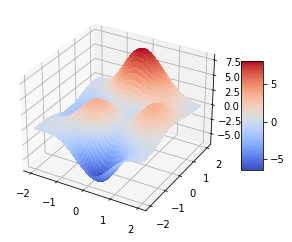

In [3]:
x1, x2 = np.meshgrid(np.arange(-2, 2, 0.01), np.arange(-2, 2, 0.01))
y = peak2d(x1, x2)

fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
# Plot the surface.
surf = ax.plot_surface(x1, x2, y, cmap=cm.coolwarm, linewidth=0.01, antialiased=False)
# Add a color bar which maps values to colors.
fig.colorbar(surf, shrink=0.5, aspect=5)
plt.show()

## Approximate the function

To fit a model, we need to reshape our data. We concatenate the values
of ``x1`` and ``x2`` in an array ``X`` and make ``y`` one dimensional.




In [4]:
X = np.concatenate([x1.ravel().reshape(-1, 1), x2.ravel().reshape(-1, 1)], axis=1)
y = y.ravel()

To approximate the function, we use a ``Pipeline`` with polynomial
features and a neural-network regressor. We do a relatively small
neural-network.




In [5]:
# Run our regression
layers = [30] * 2
regression = MLPRegressor(hidden_layer_sizes=layers, activation="relu")
pipe = make_pipeline(PolynomialFeatures(), regression)
pipe.fit(X=X, y=y)

,steps,"[('polynomialfeatures', ...), ('mlpregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,degree,2
,interaction_only,False
,include_bias,True
,order,'C'
,loss,'squared_error'
,hidden_layer_sizes,"[30, 30]"
,activation,'relu'


To test the accuracy of the approximation, we take a random sample of
points, and we print the $R^2$ value and the maximal error.




In [6]:
X_test = np.random.random((100, 2)) * 4 - 2

r2_score = metrics.r2_score(peak2d(X_test[:, 0], X_test[:, 1]), pipe.predict(X_test))
max_error = metrics.max_error(peak2d(X_test[:, 0], X_test[:, 1]), pipe.predict(X_test))
print("R2 error {}, maximal error {}".format(r2_score, max_error))

R2 error 0.9999011065666904, maximal error 0.09993635244791133


While the $R^2$ value is good, the maximal error is quite high.
For the purpose of this example we still deem it acceptable. We plot the
function.




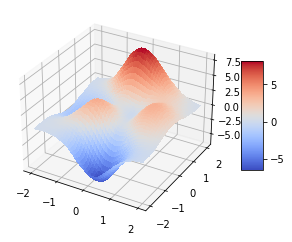

In [7]:
fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
# Plot the surface.
surf = ax.plot_surface(
    x1,
    x2,
    pipe.predict(X).reshape(x1.shape),
    cmap=cm.coolwarm,
    linewidth=0.01,
    antialiased=False,
)
# Add a color bar which maps values to colors.
fig.colorbar(surf, shrink=0.5, aspect=5)
plt.show()

Visually, the approximation looks close enough to the original function.

## Build and Solve the Optimization Model

We now turn to the optimization model. For this model we want to find
the minimal value of ``y_approx`` which is the approximation given by
our pipeline on the interval.

Note that in this simple example, we don’t use matrix variables but
regular Gurobi variables instead.




In [8]:
m = gp.Model()

x = m.addVars(2, lb=-2, ub=2, name="x")
y_approx = m.addVar(lb=-GRB.INFINITY, name="y")

m.setObjective(y_approx, gp.GRB.MINIMIZE)

# add "surrogate constraint"
pred_constr = add_predictor_constr(m, pipe, x, y_approx)

pred_constr.print_stats()

Set parameter Username
Academic license - for non-commercial use only - expires 2026-02-19
Warning for adding constraints: zero or small (< 1e-13) coefficients, ignored
Model for pipe:
126 variables
61 constraints
6 quadratic constraints
60 general constraints
Input has shape (1, 2)
Output has shape (1, 1)

Pipeline has 2 steps:

--------------------------------------------------------------------------------
Step            Output Shape    Variables              Constraints              
                                                Linear    Quadratic      General
poly_feat             (1, 6)            6            0            6            0

dense                (1, 30)           60           30            0           30 (relu)

dense0               (1, 30)           60           30            0           30 (relu)

dense1                (1, 1)            0            1            0            0


--------------------------------------------------------------------------------


Now call ``optimize``. Since we use polynomial features the resulting
model is a non-convex quadratic problem. In Gurobi, we need to set the
parameter ``NonConvex`` to 2 to be able to solve it.




In [9]:
m.Params.TimeLimit = 20
m.Params.MIPGap = 0.1
m.Params.NonConvex = 2

m.optimize()

Set parameter TimeLimit to value 20
Set parameter MIPGap to value 0.1
Set parameter NonConvex to value 2
Gurobi Optimizer version 12.0.1 build v12.0.1rc0 (linux64 - "Ubuntu 22.04.5 LTS")

CPU model: Intel(R) Core(TM) i5-1035G1 CPU @ 1.00GHz, instruction set [SSE2|AVX|AVX2|AVX512]
Thread count: 4 physical cores, 8 logical processors, using up to 8 threads

Non-default parameters:
TimeLimit  20
MIPGap  0.1
NonConvex  2

Optimize a model with 61 rows, 129 columns and 1042 nonzeros
Model fingerprint: 0xbc3742a8
Model has 6 quadratic constraints
Model has 60 simple general constraints
  60 MAX
Variable types: 129 continuous, 0 integer (0 binary)
Coefficient statistics:
  Matrix range     [2e-12, 2e+00]
  QMatrix range    [1e+00, 1e+00]
  QLMatrix range   [1e+00, 1e+00]
  Objective range  [1e+00, 1e+00]
  Bounds range     [2e+00, 2e+00]
  RHS range        [1e-02, 7e-01]
  QRHS range       [1e+00, 1e+00]
Presolve added 79 rows and 16 columns
Presolve time: 0.01s
Presolved: 150 rows, 146 colum

After solving the model, we check the error in the estimate of the
Gurobi solution.




In [10]:
print(
    "Maximum error in approximating the regression {:.6}".format(
        np.max(pred_constr.get_error())
    )
)

Maximum error in approximating the regression 9.87786e-08


Finally, we look at the solution and the objective value found.




In [11]:
print(
    f"solution point of the approximated problem ({x[0].X:.4}, {x[1].X:.4}), "
    + f"objective value {m.ObjVal}."
)
print(
    f"Function value at the solution point {peak2d(x[0].X, x[1].X)} error {abs(peak2d(x[0].X, x[1].X) - m.ObjVal)}."
)

solution point of the approximated problem (0.2168, -1.62), objective value -6.553787111467424.
Function value at the solution point -6.549160038092661 error 0.004627073374763313.


The difference between the function and the approximation at the
computed solution point is noticeable, but the point we found is
reasonably close to the actual global minimum. Depending on the use case
this might be deemed acceptable. Of course, training a larger network
should result in a better approximation.




Copyright © 2023 Gurobi Optimization, LLC


